# Descripcipción del proyecto

Film Junky Union, una nueva comunidad vanguardista para los aficionados de las películas clásicas, está desarrollando un sistema para filtrar y categorizar reseñas de películas. Tu objetivo es entrenar un modelo para detectar las críticas negativas de forma automática. Para lograrlo, utilizarás un conjunto de datos de reseñas de películas de IMDB con leyendas de polaridad para construir un modelo para clasificar las reseñas positivas y negativas. Este deberá alcanzar un valor F1 de al menos 0.85.

## Inicialización

In [2]:
import math

import numpy as np
import pandas as pd

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from tqdm.auto import tqdm

/Users/carloscarranza/miniconda3/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
%matplotlib inline
%config InlineBackend.figure_format = 'png'
# la siguiente línea proporciona gráficos de mejor calidad en pantallas HiDPI
# %config InlineBackend.figure_format = 'retina'

# el nombre del estilo cambió en las versiones nuevas de matplotlib, así que intentamos primero el de la plataforma y si falla usamos el local
try:
    plt.style.use('seaborn')
except OSError:
    plt.style.use('seaborn-v0_8')

In [3]:
# esto es para usar progress_apply, puedes leer más en https://pypi.org/project/tqdm/#pandas-integration
tqdm.pandas()

## Cargar datos

**Objetivo:** cargar el archivo `imdb_reviews.tsv` y revisar su tamaño, sus columnas y si tiene valores ausentes, para confirmar que los datos quedan listos antes de empezar a trabajar con ellos.

In [4]:
# ahora vamos a cargar los datos, primero intentamos la ruta local y si no existe usamos la ruta de la plataforma
try:
    df_reviews = pd.read_csv('imdb_reviews.tsv', sep='\t', dtype={'votes': 'Int64'})
except FileNotFoundError:
    df_reviews = pd.read_csv('/datasets/imdb_reviews.tsv', sep='\t', dtype={'votes': 'Int64'})

In [5]:
# revisamos la información general del dataframe
df_reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47331 entries, 0 to 47330
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   tconst           47331 non-null  object 
 1   title_type       47331 non-null  object 
 2   primary_title    47331 non-null  object 
 3   original_title   47331 non-null  object 
 4   start_year       47331 non-null  int64  
 5   end_year         47331 non-null  object 
 6   runtime_minutes  47331 non-null  object 
 7   is_adult         47331 non-null  int64  
 8   genres           47331 non-null  object 
 9   average_rating   47329 non-null  float64
 10  votes            47329 non-null  Int64  
 11  review           47331 non-null  object 
 12  rating           47331 non-null  int64  
 13  sp               47331 non-null  object 
 14  pos              47331 non-null  int64  
 15  ds_part          47331 non-null  object 
 16  idx              47331 non-null  int64  
dtypes: Int64(1),

In [6]:
# vemos las primeras filas para conocer las columnas
df_reviews.head()

,tconst,title_type,primary_title,original_title,start_year,end_year,runtime_minutes,is_adult,genres,average_rating,votes,review,rating,sp,pos,ds_part,idx
0,tt0068152,movie,$,$,1971,\N,121,0,"Comedy,Crime,Drama",6.3,2218,The pakage implies that Warren Beatty and Gold...,1,neg,0,train,8335
1,tt0068152,movie,$,$,1971,\N,121,0,"Comedy,Crime,Drama",6.3,2218,How the hell did they get this made?! Presenti...,1,neg,0,train,8336
2,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,There is no real story the film seems more lik...,3,neg,0,test,2489
3,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,Um .... a serious film about troubled teens in...,7,pos,1,test,9280
4,tt0313150,short,'15','15',2002,\N,25,0,"Comedy,Drama,Short",6.3,184,I'm totally agree with GarryJohal from Singapo...,9,pos,1,test,9281


In [7]:
# confirmamos cuántas filas y columnas tenemos
df_reviews.shape

(47331, 17)

**Conclusión:** el conjunto tiene 47331 filas y 17 columnas. Las columnas que voy a usar para el modelo son `review` (el texto de la reseña), `pos` (la etiqueta, 0 negativa y 1 positiva) y `ds_part` (si la fila es de entrenamiento o de prueba). En el `info()` veo que `review`, `pos` y `ds_part` no tienen valores ausentes, los únicos ausentes están en `average_rating` y `votes` (2 cada una), que no uso para el modelo. Por eso no necesito limpiar nada en este punto. El balance de las clases y la división entrenamiento/prueba los analizo en el EDA.

## Preprocesamiento de los datos

**Objetivo:** antes de modelar reviso si hay filas duplicadas, textos de reseña repetidos y valores ausentes, para decidir si hace falta limpiar algo.

In [8]:
# revisamos filas totalmente duplicadas y textos de reseña repetidos
print('Filas totalmente duplicadas:', df_reviews.duplicated().sum())
print('Reseñas con texto repetido:', df_reviews['review'].duplicated().sum())

# revisamos los valores ausentes por columna
print()
print('Valores ausentes por columna:')
print(df_reviews.isna().sum())

# de los textos repetidos, revisamos si alguno cruza train y test o tiene etiqueta distinta entre copias
conteo = df_reviews['review'].value_counts()
textos_repetidos = conteo[conteo > 1].index

cruzan = 0
etiqueta_distinta = 0
for texto in textos_repetidos:
    copias = df_reviews[df_reviews['review'] == texto]
    if copias['ds_part'].nunique() > 1:
        cruzan = cruzan + 1
    if copias['pos'].nunique() > 1:
        etiqueta_distinta = etiqueta_distinta + 1

print()
print('Textos repetidos que aparecen en train y test:', cruzan)
print('Textos repetidos con etiqueta distinta entre copias:', etiqueta_distinta)

Filas totalmente duplicadas: 0


Reseñas con texto repetido: 91

Valores ausentes por columna:
tconst             0
title_type         0
primary_title      0
original_title     0
start_year         0
end_year           0
runtime_minutes    0
is_adult           0
genres             0
average_rating     2
votes              2
review             0
rating             0
sp                 0
pos                0
ds_part            0
idx                0
dtype: int64

Textos repetidos que aparecen en train y test: 1
Textos repetidos con etiqueta distinta entre copias: 0


**Conclusión:** no hay filas totalmente duplicadas. Hay 91 reseñas con texto repetido, que son el 0.19% de los datos; ninguna tiene etiqueta `pos` distinta entre sus copias y solo 1 texto aparece en train y test a la vez, así que el riesgo de fuga es mínimo. Los únicos valores ausentes están en `average_rating` y `votes` (2 cada una), columnas que no uso para el modelo. Por eso decidí no eliminar ni rellenar nada y conservar la división entrenamiento/prueba que ya trae el conjunto.

## EDA

**Objetivo:** explorar los datos para entender cuántas reseñas y películas hay y cómo se distribuyen a lo largo de los años, y sobre todo revisar el balance entre reseñas positivas y negativas.

Veamos el número de películas y reseñas a lo largo de los años.

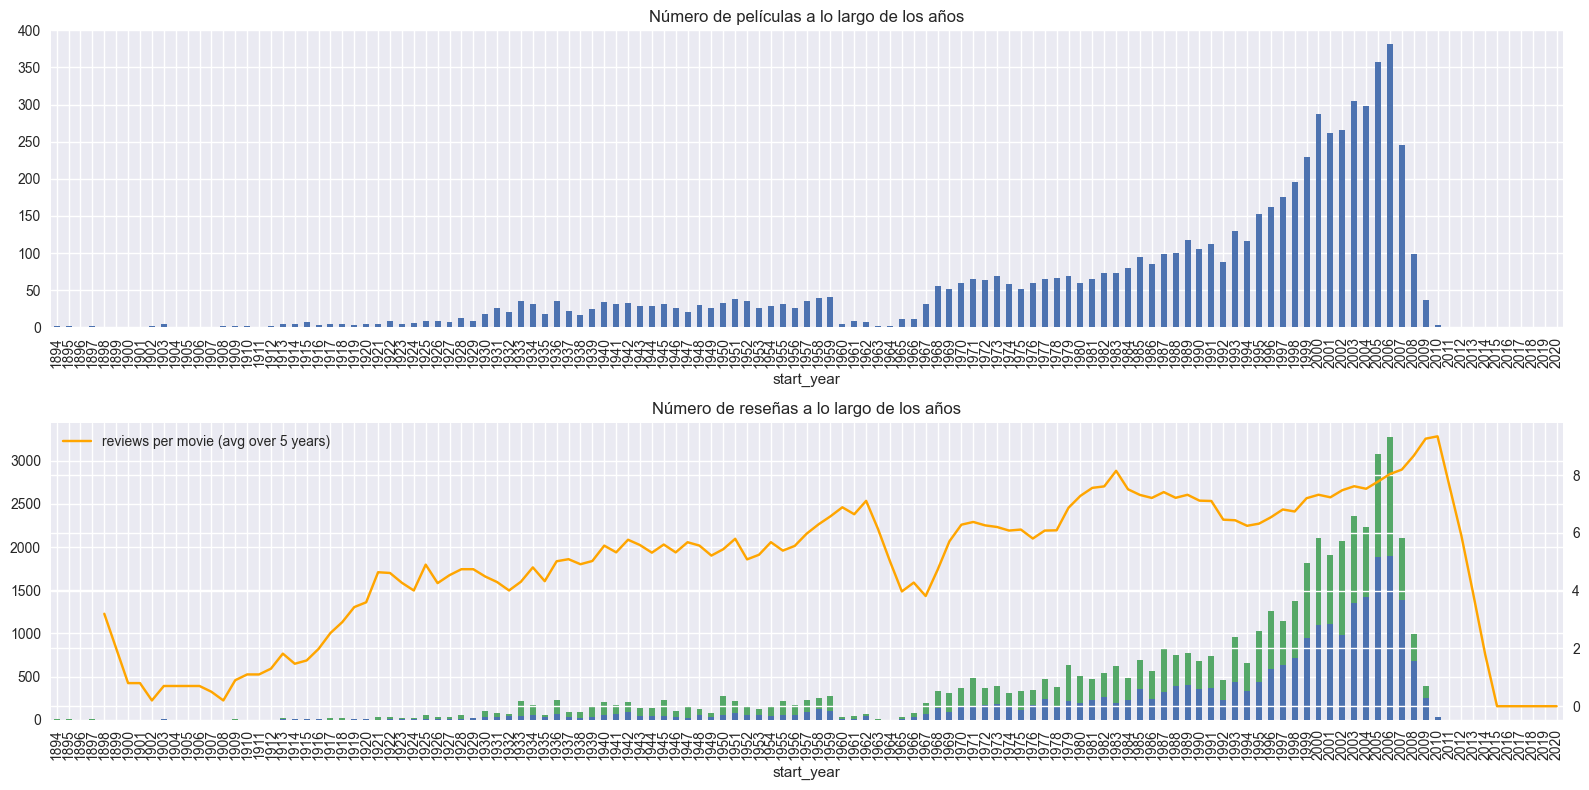

In [9]:
fig, axs = plt.subplots(2, 1, figsize=(16, 8))

ax = axs[0]

dft1 = df_reviews[['tconst', 'start_year']].drop_duplicates() \
    ['start_year'].value_counts().sort_index()
dft1 = dft1.reindex(index=np.arange(dft1.index.min(), max(dft1.index.max(), 2021))).fillna(0)
dft1.plot(kind='bar', ax=ax)
ax.set_title('Número de películas a lo largo de los años')

ax = axs[1]

dft2 = df_reviews.groupby(['start_year', 'pos'])['pos'].count().unstack()
dft2 = dft2.reindex(index=np.arange(dft2.index.min(), max(dft2.index.max(), 2021))).fillna(0)

dft2.plot(kind='bar', stacked=True, label='#reviews (neg, pos)', ax=ax)

dft2 = df_reviews['start_year'].value_counts().sort_index()
dft2 = dft2.reindex(index=np.arange(dft2.index.min(), max(dft2.index.max(), 2021))).fillna(0)
dft3 = (dft2/dft1).fillna(0)
axt = ax.twinx()
dft3.reset_index(drop=True).rolling(5).mean().plot(color='orange', label='reviews per movie (avg over 5 years)', ax=axt)

lines, labels = axt.get_legend_handles_labels()
ax.legend(lines, labels, loc='upper left')

ax.set_title('Número de reseñas a lo largo de los años')

fig.tight_layout()

Veamos la distribución del número de reseñas por película con el conteo exacto y KDE (solo para saber cómo puede diferir del conteo exacto)

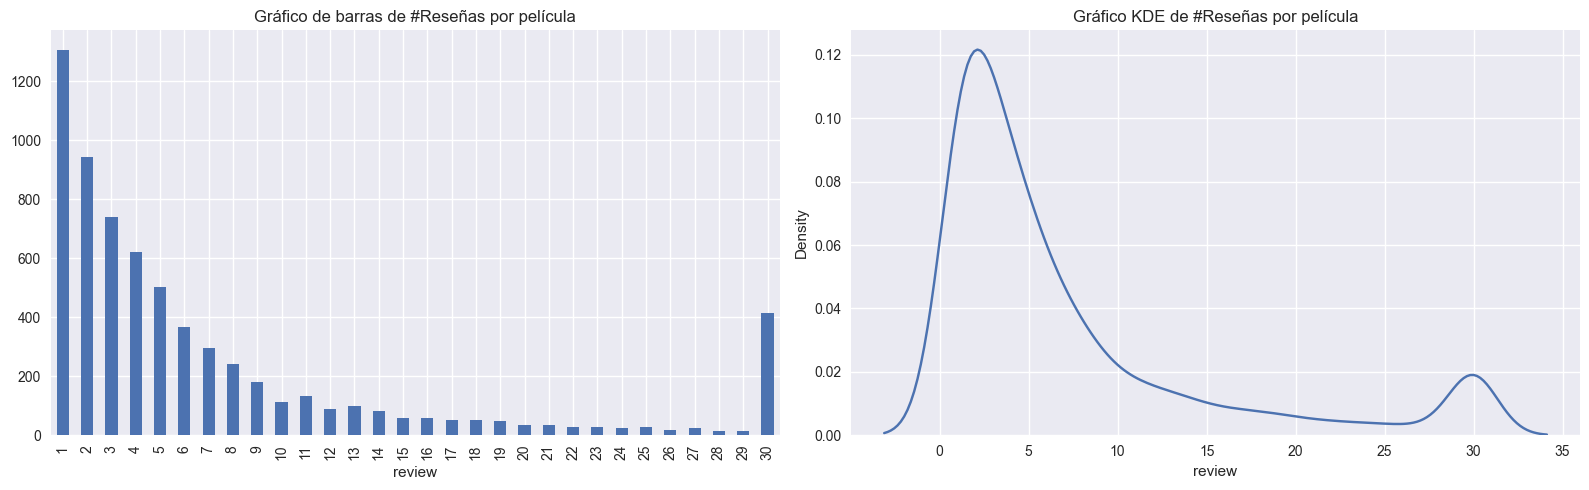

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5))

ax = axs[0]
dft = df_reviews.groupby('tconst')['review'].count() \
    .value_counts() \
    .sort_index()
dft.plot.bar(ax=ax)
ax.set_title('Gráfico de barras de #Reseñas por película')

ax = axs[1]
dft = df_reviews.groupby('tconst')['review'].count()
sns.kdeplot(dft, ax=ax)
ax.set_title('Gráfico KDE de #Reseñas por película')

fig.tight_layout()

In [11]:
# revisamos el balance de clases por parte del conjunto, en porcentaje
print('Balance en entrenamiento (porcentaje):')
train_pos = df_reviews.query('ds_part == "train"')['pos']
print(round(train_pos.value_counts(normalize=True) * 100, 2))

print()
print('Balance en prueba (porcentaje):')
test_pos = df_reviews.query('ds_part == "test"')['pos']
print(round(test_pos.value_counts(normalize=True) * 100, 2))

Balance en entrenamiento (porcentaje):
pos
0    50.06
1    49.94
Name: proportion, dtype: float64

Balance en prueba (porcentaje):
pos
0    50.15
1    49.85
Name: proportion, dtype: float64


In [12]:
df_reviews['pos'].value_counts()

pos
0    23715
1    23616
Name: count, dtype: int64

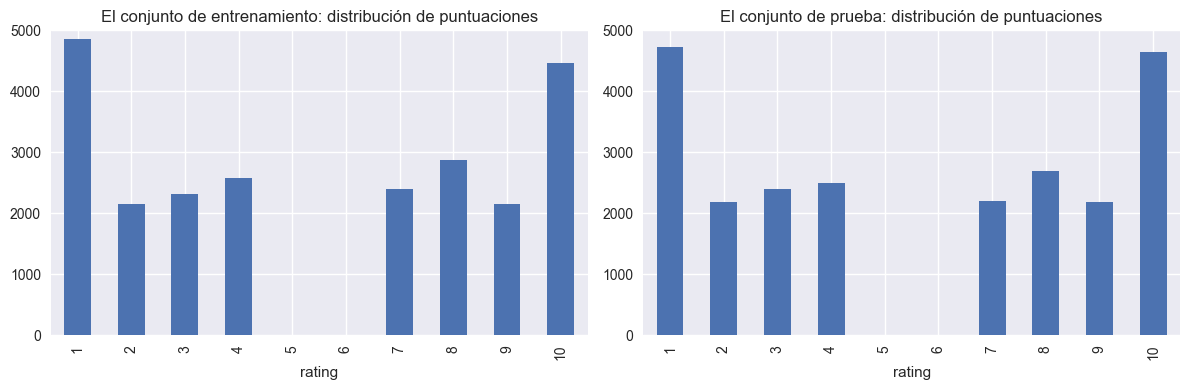

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

ax = axs[0]
dft = df_reviews.query('ds_part == "train"')['rating'].value_counts().sort_index()
dft = dft.reindex(index=np.arange(min(dft.index.min(), 1), max(dft.index.max(), 11))).fillna(0)
dft.plot.bar(ax=ax)
ax.set_ylim([0, 5000])
ax.set_title('El conjunto de entrenamiento: distribución de puntuaciones')

ax = axs[1]
dft = df_reviews.query('ds_part == "test"')['rating'].value_counts().sort_index()
dft = dft.reindex(index=np.arange(min(dft.index.min(), 1), max(dft.index.max(), 11))).fillna(0)
dft.plot.bar(ax=ax)
ax.set_ylim([0, 5000])
ax.set_title('El conjunto de prueba: distribución de puntuaciones')

fig.tight_layout()

Distribución de reseñas negativas y positivas a lo largo de los años para dos partes del conjunto de datos

/var/folders/tp/tccs84bn713ckxl_07sqv3_40000gn/T/ipykernel_21253/1324160450.py:14: UserWarning: 

Support for alternate kernels has been removed; using Gaussian kernel.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
/var/folders/tp/tccs84bn713ckxl_07sqv3_40000gn/T/ipykernel_21253/1324160450.py:15: UserWarning: 

Support for alternate kernels has been removed; using Gaussian kernel.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
/var/folders/tp/tccs84bn713ckxl_07sqv3_40000gn/T/ipykernel_21253/1324160450.py:30: UserWarning: 

Support for alternate kernels has been removed; using Gaussian kernel.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
/var/folders/tp/tccs84bn713ckxl_07sqv3_40000gn/T/ip

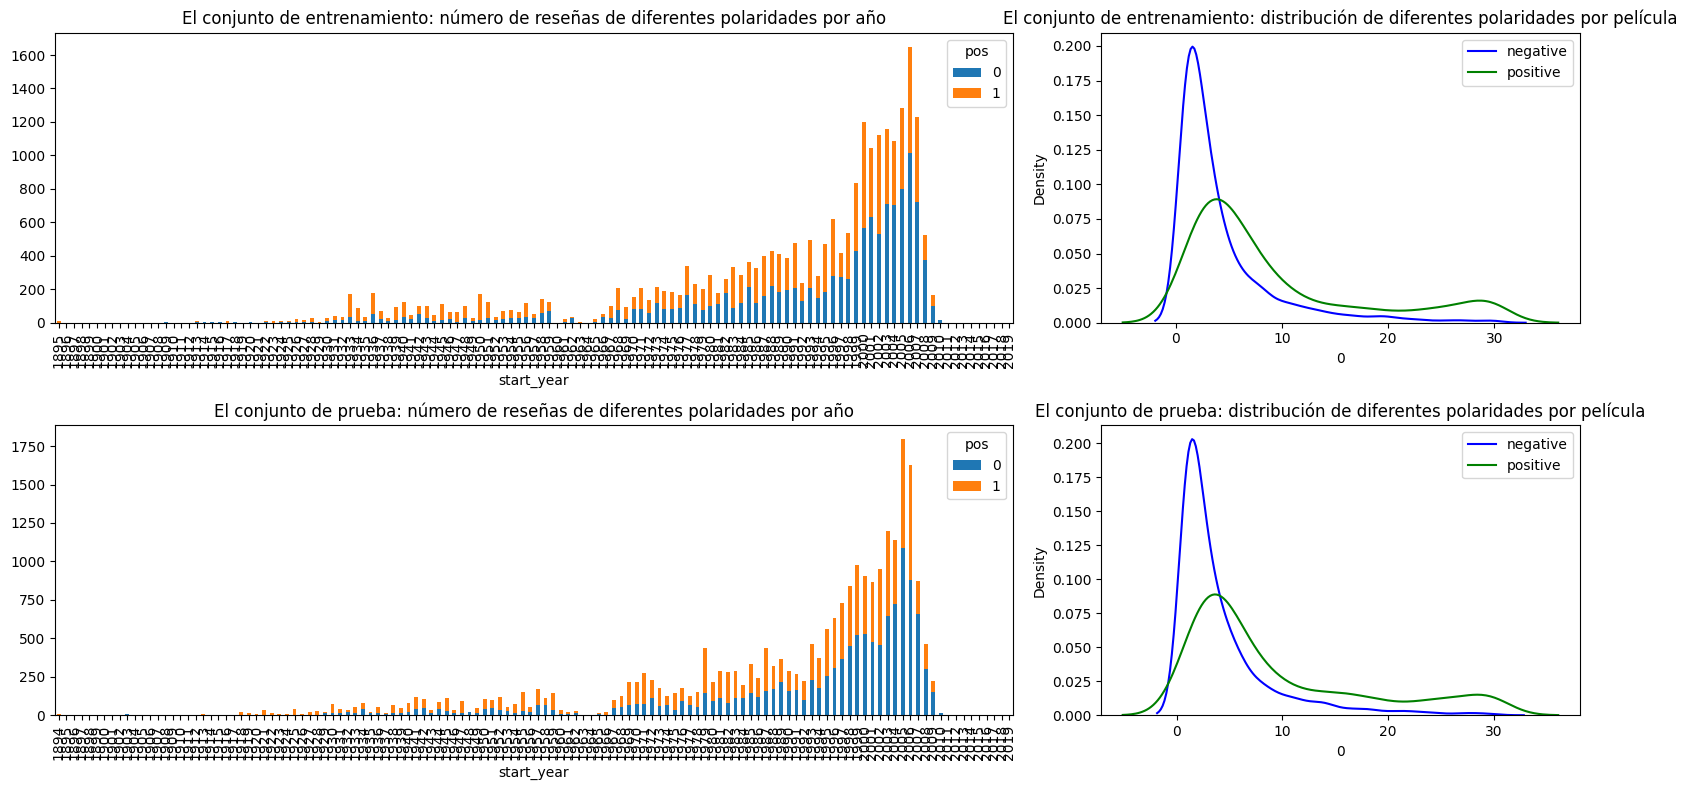

In [5]:
fig, axs = plt.subplots(2, 2, figsize=(16, 8), gridspec_kw=dict(width_ratios=(2, 1), height_ratios=(1, 1)))

ax = axs[0][0]

dft = df_reviews.query('ds_part == "train"').groupby(['start_year', 'pos'])['pos'].count().unstack()
dft.index = dft.index.astype('int')
dft = dft.reindex(index=np.arange(dft.index.min(), max(dft.index.max(), 2020))).fillna(0)
dft.plot(kind='bar', stacked=True, ax=ax)
ax.set_title('El conjunto de entrenamiento: número de reseñas de diferentes polaridades por año')

ax = axs[0][1]

dft = df_reviews.query('ds_part == "train"').groupby(['tconst', 'pos'])['pos'].count().unstack()
sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
ax.legend()
ax.set_title('El conjunto de entrenamiento: distribución de diferentes polaridades por película')

ax = axs[1][0]

dft = df_reviews.query('ds_part == "test"').groupby(['start_year', 'pos'])['pos'].count().unstack()
dft.index = dft.index.astype('int')
dft = dft.reindex(index=np.arange(dft.index.min(), max(dft.index.max(), 2020))).fillna(0)
dft.plot(kind='bar', stacked=True, ax=ax)
ax.set_title('El conjunto de prueba: número de reseñas de diferentes polaridades por año')

ax = axs[1][1]

dft = df_reviews.query('ds_part == "test"').groupby(['tconst', 'pos'])['pos'].count().unstack()
sns.kdeplot(dft[0], color='blue', label='negative', kernel='epa', ax=ax)
sns.kdeplot(dft[1], color='green', label='positive', kernel='epa', ax=ax)
ax.legend()
ax.set_title('El conjunto de prueba: distribución de diferentes polaridades por película')

fig.tight_layout()

**Conclusión:** las reseñas están repartidas a lo largo de muchos años y la mayoría de las películas tiene pocas reseñas. Lo más importante para el modelo es el balance de clases: a nivel global hay 23715 reseñas negativas y 23616 positivas, un 50.1% frente a 49.9%, y ese mismo equilibrio se mantiene en entrenamiento (50.06 / 49.94) y en prueba (50.15 / 49.85). Las clases están balanceadas, así que no hay desequilibrio que corregir y no necesito ajustar pesos ni remuestrear. Aun así voy a medir con F1, porque es la métrica objetivo del proyecto.

## Procedimiento de evaluación

Composición de una rutina de evaluación que se pueda usar para todos los modelos en este proyecto

In [15]:
import sklearn.metrics as metrics
def evaluate_model(model, train_features, train_target, test_features, test_target):

    eval_stats = {}

    fig, axs = plt.subplots(1, 3, figsize=(20, 6))

    for type, features, target in (('train', train_features, train_target), ('test', test_features, test_target)):

        eval_stats[type] = {}

        pred_target = model.predict(features)
        pred_proba = model.predict_proba(features)[:, 1]

        # F1
        f1_thresholds = np.arange(0, 1.01, 0.05)
        f1_scores = [metrics.f1_score(target, pred_proba>=threshold) for threshold in f1_thresholds]

        # ROC
        fpr, tpr, roc_thresholds = metrics.roc_curve(target, pred_proba)
        roc_auc = metrics.roc_auc_score(target, pred_proba)
        eval_stats[type]['ROC AUC'] = roc_auc

        # PRC
        precision, recall, pr_thresholds = metrics.precision_recall_curve(target, pred_proba)
        aps = metrics.average_precision_score(target, pred_proba)
        eval_stats[type]['APS'] = aps

        if type == 'train':
            color = 'blue'
        else:
            color = 'green'

        # Valor F1
        ax = axs[0]
        max_f1_score_idx = np.argmax(f1_scores)
        ax.plot(f1_thresholds, f1_scores, color=color, label=f'{type}, max={f1_scores[max_f1_score_idx]:.2f} @ {f1_thresholds[max_f1_score_idx]:.2f}')
        # establecer cruces para algunos umbrales
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(f1_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(f1_thresholds[closest_value_idx], f1_scores[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('threshold')
        ax.set_ylabel('F1')
        ax.legend(loc='lower center')
        ax.set_title(f'Valor F1')

        # ROC
        ax = axs[1]
        ax.plot(fpr, tpr, color=color, label=f'{type}, ROC AUC={roc_auc:.2f}')
        # establecer cruces para algunos umbrales
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(roc_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(fpr[closest_value_idx], tpr[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.plot([0, 1], [0, 1], color='grey', linestyle='--')
        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('FPR')
        ax.set_ylabel('TPR')
        ax.legend(loc='lower center')
        ax.set_title(f'Curva ROC')

        # PRC
        ax = axs[2]
        ax.plot(recall, precision, color=color, label=f'{type}, AP={aps:.2f}')
        # establecer cruces para algunos umbrales
        for threshold in (0.2, 0.4, 0.5, 0.6, 0.8):
            closest_value_idx = np.argmin(np.abs(pr_thresholds-threshold))
            marker_color = 'orange' if threshold != 0.5 else 'red'
            ax.plot(recall[closest_value_idx], precision[closest_value_idx], color=marker_color, marker='X', markersize=7)
        ax.set_xlim([-0.02, 1.02])
        ax.set_ylim([-0.02, 1.02])
        ax.set_xlabel('recall')
        ax.set_ylabel('precision')
        ax.legend(loc='lower center')
        ax.set_title(f'PRC')

        eval_stats[type]['Accuracy'] = metrics.accuracy_score(target, pred_target)
        eval_stats[type]['F1'] = metrics.f1_score(target, pred_target)

    df_eval_stats = pd.DataFrame(eval_stats)
    df_eval_stats = df_eval_stats.round(2)
    df_eval_stats = df_eval_stats.reindex(index=('Accuracy', 'F1', 'APS', 'ROC AUC'))

    print(df_eval_stats)

    return

## Normalización

Suponemos que todos los modelos a continuación aceptan textos en minúsculas y sin dígitos, signos de puntuación, etc.

**Objetivo:** dejar el texto de las reseñas listo para vectorizar, en minúsculas y sin signos ni números, que es lo que esperan los modelos.

In [16]:
# normalizamos el texto: lo pasamos a minúsculas y dejamos solo letras y espacios
import re

def normalizar_texto(texto):
    texto = texto.lower()
    texto = re.sub(r'[^a-z ]', ' ', texto)
    texto = ' '.join(texto.split())
    return texto

df_reviews['review_norm'] = df_reviews['review'].apply(normalizar_texto)
df_reviews[['review', 'review_norm']].head()

,review,review_norm
0,The pakage implies that Warren Beatty and Gold...,the pakage implies that warren beatty and gold...
1,How the hell did they get this made?! Presenti...,how the hell did they get this made presenting...
2,There is no real story the film seems more lik...,there is no real story the film seems more lik...
3,Um .... a serious film about troubled teens in...,um a serious film about troubled teens in sing...
4,I'm totally agree with GarryJohal from Singapo...,i m totally agree with garryjohal from singapo...


**Conclusión:** apliqué una función que pasa cada reseña a minúsculas y deja solo letras y espacios, y guardé el resultado en la columna `review_norm`. Con esto el texto queda limpio para convertirlo en vectores TF-IDF.

## División entrenamiento / prueba

Por fortuna, todo el conjunto de datos ya está dividido en partes de entrenamiento/prueba; 'ds_part' es el indicador correspondiente.

In [17]:
df_reviews_train = df_reviews.query('ds_part == "train"').copy()
df_reviews_test = df_reviews.query('ds_part == "test"').copy()

train_target = df_reviews_train['pos']
test_target = df_reviews_test['pos']

print(df_reviews_train.shape)
print(df_reviews_test.shape)

(23796, 18)
(23535, 18)


## Trabajar con modelos

**Objetivo:** entrenar y comparar tres modelos para clasificar las reseñas: un modelo constante como línea base, una regresión logística sobre TF-IDF y una potenciación del gradiente (LightGBM) sobre las mismas características. La meta es superar un F1 de 0.85 en el conjunto de prueba.

### Modelo 0 - Constante

In [18]:
from sklearn.dummy import DummyClassifier

In [19]:
# entrenamos un modelo constante como línea base, siempre predice la clase más frecuente
model_0 = DummyClassifier(strategy='most_frequent', random_state=12345)
model_0.fit(df_reviews_train['review_norm'], train_target)

pred_train_0 = model_0.predict(df_reviews_train['review_norm'])
pred_test_0 = model_0.predict(df_reviews_test['review_norm'])

print('Modelo 0 F1 en entrenamiento:', round(metrics.f1_score(train_target, pred_train_0), 4))
print('Modelo 0 F1 en prueba:', round(metrics.f1_score(test_target, pred_test_0), 4))

Modelo 0 F1 en entrenamiento: 0.0
Modelo 0 F1 en prueba: 0.0


### Modelo 1 - NLTK, TF-IDF y LR

TF-IDF

In [20]:
import nltk

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from nltk.corpus import stopwords

In [21]:
# descargamos las stopwords en inglés y creamos el vectorizador TF-IDF
nltk.download('stopwords')
stop_words = stopwords.words('english')
tfidf_vectorizer_1 = TfidfVectorizer(stop_words=stop_words)

# ajustamos el vectorizador con el texto de entrenamiento y transformamos ambos conjuntos
train_features_1 = tfidf_vectorizer_1.fit_transform(df_reviews_train['review_norm'])
test_features_1 = tfidf_vectorizer_1.transform(df_reviews_test['review_norm'])

print('Forma de las características de entrenamiento:', train_features_1.shape)

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/carloscarranza/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Forma de las características de entrenamiento: (23796, 71531)


In [22]:
# entrenamos la regresión logística con las características TF-IDF
model_1 = LogisticRegression(random_state=12345, max_iter=1000)
model_1.fit(train_features_1, train_target)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",12345
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 

          train  test
Accuracy   0.94  0.88
F1         0.94  0.88
APS        0.98  0.95
ROC AUC    0.98  0.95


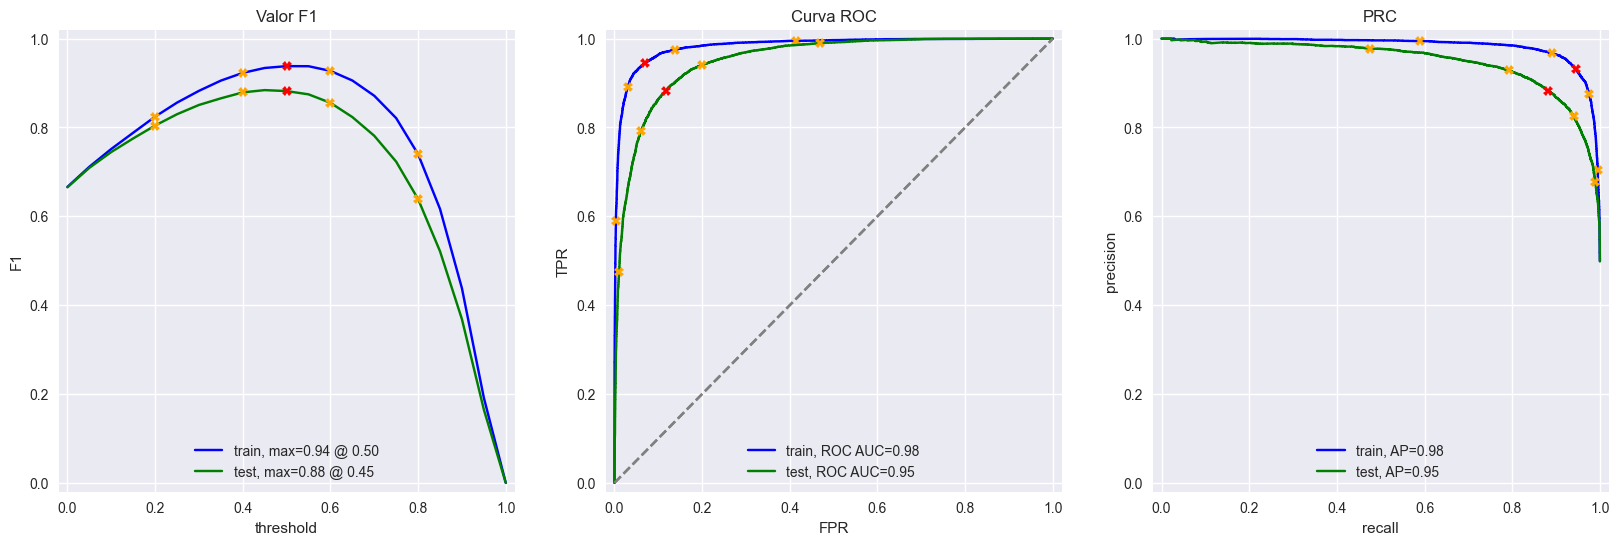

In [23]:
evaluate_model(model_1, train_features_1, train_target, test_features_1, test_target)

### Modelo 2 - TF-IDF y LGBMClassifier

In [24]:
from lightgbm import LGBMClassifier

In [25]:
# entrenamos la potenciación del gradiente con las mismas características TF-IDF del Modelo 1
model_2 = LGBMClassifier(random_state=12345)
model_2.fit(train_features_1, train_target)

[LightGBM] [Info] Number of positive: 11884, number of negative: 11912


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.572861 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 515926
[LightGBM] [Info] Number of data points in the train set: 23796, number of used features: 11526
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.499412 -> initscore=-0.002353
[LightGBM] [Info] Start training from score -0.002353


,random_state,12345
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001


          train  test
Accuracy   0.91  0.86
F1         0.92  0.86
APS        0.97  0.93
ROC AUC    0.97  0.94


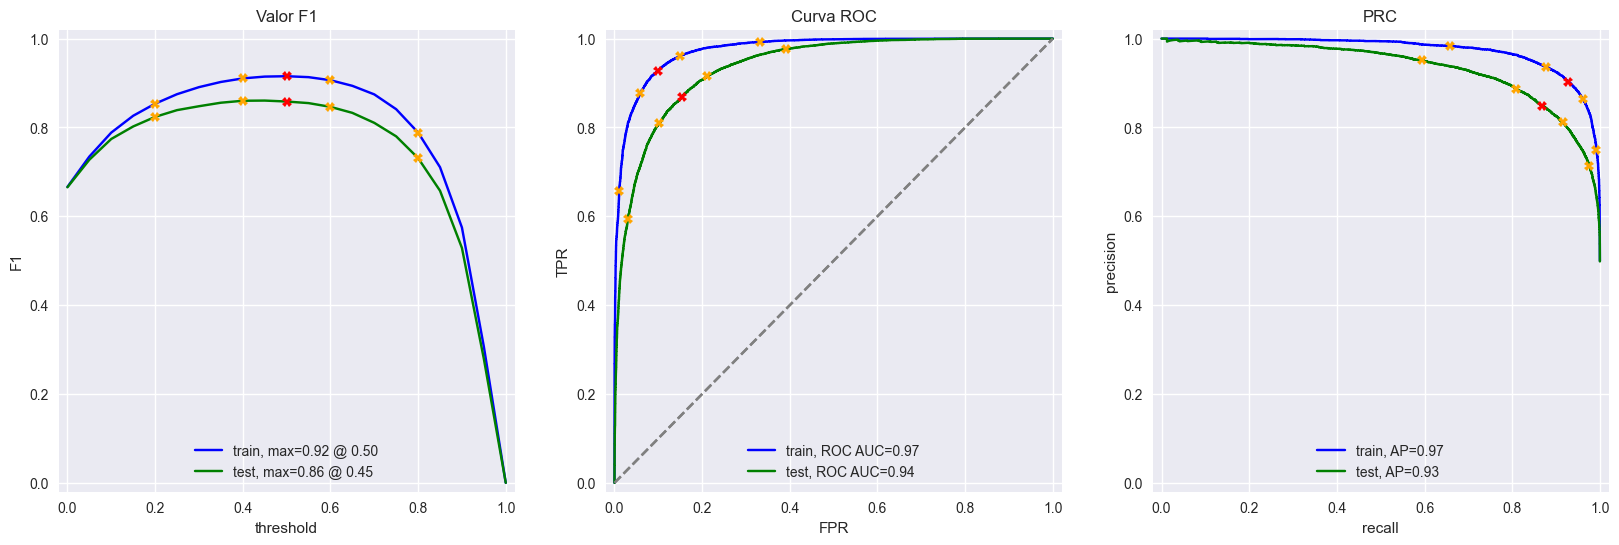

In [26]:
evaluate_model(model_2, train_features_1, train_target, test_features_1, test_target)

**Conclusión:** el modelo constante da un F1 de 0.0 en prueba, porque al predecir siempre la clase mayoritaria no detecta ninguna reseña positiva; sirve para ver el piso de la métrica. La regresión logística (Modelo 1) alcanza un F1 de 0.88 en prueba y la potenciación del gradiente (Modelo 2) un 0.86. Los dos superan el umbral de 0.85, pero la regresión logística queda por encima y además entrena en una fracción del tiempo que tarda LightGBM. Me quedo con la regresión logística como mejor modelo.

## Mis reseñas

**Objetivo:** escribir unas reseñas nuevas y clasificarlas con el Modelo 1 y el Modelo 2, para ver cómo se comportan fuera del conjunto de datos y comparar las probabilidades que da cada uno.

In [27]:
# estas son algunas reseñas de ejemplo para probar los modelos, se pueden cambiar por otras
my_reviews = pd.DataFrame([
    'I did not simply like it, not my kind of movie.',
    'Well, I was bored and felt asleep in the middle of the movie.',
    'I was really fascinated with the movie',
    'Even the actors looked really old and disinterested, and they got paid to be in the movie. What a soulless cash grab.',
    "I didn't expect the reboot to be so good! Writers really cared about the source material",
    "The movie had its upsides and downsides, but I feel like overall it's a decent flick. I could see myself going to see it again.",
    "What a rotten attempt at a comedy. Not a single joke lands, everyone acts annoying and loud, even kids won't like this!",
    'Launching on Netflix was a brave move & I really appreciate being able to binge on episode after episode, of this exciting intelligent new drama.'
], columns=['review'])

# aplicamos la misma normalización que al conjunto principal
my_reviews['review_norm'] = my_reviews['review'].apply(normalizar_texto)
my_reviews

,review,review_norm
0,"I did not simply like it, not my kind of movie.",i did not simply like it not my kind of movie
1,"Well, I was bored and felt asleep in the middl...",well i was bored and felt asleep in the middle...
2,I was really fascinated with the movie,i was really fascinated with the movie
3,Even the actors looked really old and disinter...,even the actors looked really old and disinter...
4,I didn't expect the reboot to be so good! Writ...,i didn t expect the reboot to be so good write...
5,"The movie had its upsides and downsides, but I...",the movie had its upsides and downsides but i ...
6,What a rotten attempt at a comedy. Not a singl...,what a rotten attempt at a comedy not a single...
7,Launching on Netflix was a brave move & I real...,launching on netflix was a brave move i really...


### Modelo 1

In [28]:
# clasificamos mis reseñas con el Modelo 1 (regresión logística)
texts = my_reviews['review_norm']
my_reviews_features = tfidf_vectorizer_1.transform(texts)
my_reviews_pred_prob = model_1.predict_proba(my_reviews_features)[:, 1]

for i in range(len(my_reviews)):
    print(round(my_reviews_pred_prob[i], 2), ':', my_reviews['review'][i][:80])

0.14 : I did not simply like it, not my kind of movie.
0.15 : Well, I was bored and felt asleep in the middle of the movie.
0.53 : I was really fascinated with the movie
0.11 : Even the actors looked really old and disinterested, and they got paid to be in 
0.3 : I didn't expect the reboot to be so good! Writers really cared about the source 
0.47 : The movie had its upsides and downsides, but I feel like overall it's a decent f
0.04 : What a rotten attempt at a comedy. Not a single joke lands, everyone acts annoyi
0.82 : Launching on Netflix was a brave move & I really appreciate being able to binge 


### Modelo 2

In [29]:
# clasificamos mis reseñas con el Modelo 2 (LightGBM), usando el mismo vectorizador
texts = my_reviews['review_norm']
my_reviews_features = tfidf_vectorizer_1.transform(texts)
my_reviews_pred_prob = model_2.predict_proba(my_reviews_features)[:, 1]

for i in range(len(my_reviews)):
    print(round(my_reviews_pred_prob[i], 2), ':', my_reviews['review'][i][:80])

0.58 : I did not simply like it, not my kind of movie.
0.46 : Well, I was bored and felt asleep in the middle of the movie.
0.59 : I was really fascinated with the movie
0.33 : Even the actors looked really old and disinterested, and they got paid to be in 
0.64 : I didn't expect the reboot to be so good! Writers really cared about the source 
0.63 : The movie had its upsides and downsides, but I feel like overall it's a decent f
0.22 : What a rotten attempt at a comedy. Not a single joke lands, everyone acts annoyi
0.66 : Launching on Netflix was a brave move & I really appreciate being able to binge 


**Conclusión:** en mis reseñas se repite lo que vi en la prueba. La regresión logística separa mejor: a las reseñas claramente negativas les da probabilidades bajas (la de la comedia pésima baja a 0.04) y a las positivas más altas (la de Netflix sube a 0.82). LightGBM deja casi todas las probabilidades cerca de 0.5, entre 0.22 y 0.66, es decir queda menos seguro. La diferencia tiene sentido: con TF-IDF el texto queda en un espacio de muchísimas dimensiones y muy disperso, y el árbol de LightGBM reparte sus cortes entre miles de palabras, así que en reseñas cortas y nuevas pocas palabras mueven el resultado y la probabilidad se queda cerca de la tasa base. La regresión logística, en cambio, suma el peso de cada palabra y reacciona más a las que tienen carga de sentimiento.

## Conclusiones

En este proyecto entrené un modelo para detectar reseñas negativas de IMDB. Primero revisé los datos: 47331 reseñas, sin filas totalmente duplicadas y con las clases balanceadas, alrededor de 50% positivas y 50% negativas tanto en entrenamiento como en prueba, así que no tuve que corregir ningún desequilibrio. Después normalicé el texto, lo pasé a minúsculas y dejé solo letras, y lo convertí en vectores con TF-IDF usando stopwords en inglés.

Comparé tres modelos. El constante dio un F1 de 0.0 y sirvió como línea base para ver el piso de la métrica. La regresión logística llegó a un F1 de 0.88 en prueba y LightGBM a 0.86; los dos superan el umbral de 0.85 que pedía el proyecto. Elegí la regresión logística como modelo final porque da el mejor F1, entrena mucho más rápido y, al probarla con reseñas escritas por mí, separa las positivas de las negativas con más claridad que LightGBM.

Lo que saco de este proyecto es que para clasificar texto vectorizado con TF-IDF un modelo lineal sencillo como la regresión logística funciona mejor y más rápido que la potenciación del gradiente, que necesita más tiempo de entrenamiento y aun así se queda por debajo.

# Lista de comprobación

- [x]  Abriste el notebook
- [x]  Cargaste y preprocesaste los datos de texto para su vectorización
- [x]  Transformaste los datos de texto en vectores
- [x]  Entrenaste y probaste los modelos
- [x]  Se alcanzó el umbral de la métrica
- [x]  Colocaste todas las celdas de código en el orden de su ejecución
- [x]  Puedes ejecutar sin errores todas las celdas de código
- [x]  Hay conclusiones